# Predicting Cardiac Diseases in Children — Introdução à Ciência de Dados (ICD)

**Autor:** Henrique Oliveira  
**Instituição:** FCUP / FEUP — Universidade do Porto  
**Data:** Dezembro de 2026  

---

## 1. Dados em Bruto (*Raw Data*)

### 1.1 Contexto e Dicionário de Variáveis
O dataset analisado (`UCMF(5).xls`, folha `UCMF_CORRIGIDO`) contém **17 873 registos clínicos** anonimizados de crianças e adolescentes (entre 0 e 19 anos), recolhidos no Real Hospital Português (Brasil). O objetivo principal do estudo é identificar os atributos mais preditivos de patologias cardíacas (`NORMAL X ANORMAL`) e construir modelos de classificação supervisionada.

De acordo com a teoria estatística, cada uma das 21 variáveis originais classifica-se na seguinte escala de medida:

| Variável | Descrição Clínica | Tipo de Dados (Pandas) | Escala Estatística |
| :--- | :--- | :--- | :--- |
| `ID` | Identificador único anonimizado do paciente | Numérico (`int64`) | **Nominal** (Identificador sem ordem/magnitude) |
| `Peso` | Massa corporal do paciente (kg) | Numérico (`float64`) | **Rácio (*Ratio-scaled*)** (Zero absoluto) |
| `Altura` | Estatura / comprimento do paciente (cm) | Numérico (`int64`) | **Rácio (*Ratio-scaled*)** (Zero absoluto) |
| `IMC` | Índice de Massa Corporal ($\text{kg/m}^2$) | Numérico (`float64`) | **Rácio (*Ratio-scaled*)** |
| `Atendimento` | Data da consulta cardiológica | Texto / Data (`object`) | **Intervalar (*Interval-scaled*)** |
| `DN` | Data de nascimento do paciente | Texto / Data (`object`) | **Intervalar (*Interval-scaled*)** |
| `IDADE` | Idade do paciente à data da consulta (anos) | Texto (`object` - corrompido) | **Rácio (*Ratio-scaled*)** |
| `Convenio` | Subsistemas / seguros de saúde | Texto (`object`) | **Nominal** |
| `PULSOS` | Avaliação dos pulsos periféricos/femorais | Texto (`object`) | **Nominal** |
| `PA SISTOLICA` | Pressão Arterial Sistólica (mmHg) | Numérico (`float64`) | **Rácio (*Ratio-scaled*)** |
| `PA DIASTOLICA` | Pressão Arterial Diastólica (mmHg) | Numérico (`float64`) | **Rácio (*Ratio-scaled*)** |
| `PPA` | Classificação clínica da Tensão Arterial | Texto (`object`) | **Ordinal** (*Normal < Pré-Hipertensão < HAS-1 < HAS-2*) |
| `NORMAL X ANORMAL` | **Variável Alvo:** Presença/ausência de cardiopatia | Texto (`object`) | **Binária** (*Normal* vs. *Anormal*) |
| `B2` | Características da 2.ª bulha cardíaca | Texto (`object`) | **Nominal** |
| `SOPRO` | Presença e tipo de sopro cardíaco | Texto (`object`) | **Nominal** |
| `FC` | Frequência Cardíaca (batimentos por minuto) | Texto (`object` - corrompido) | **Rácio (*Ratio-scaled*)** |
| `HDA 1` | História da Doença Atual (sintoma principal) | Texto (`object`) | **Nominal** |
| `HDA2` | História da Doença Atual (sintoma secundário) | Texto (`object`) | **Nominal** |
| `SEXO` | Sexo biológico do paciente | Texto (`object`) | **Nominal** |
| `MOTIVO1` | Motivo principal de encaminhamento | Texto (`object`) | **Nominal** |
| `MOTIVO2` | Motivo secundário de encaminhamento | Texto (`object`) | **Nominal** |

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual global dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

# Carregar dataset original (o notebook está em notebooks/, logo usamos ../data/raw/)
RAW_PATH = "../data/raw/UCMF(5).xls"
df_raw = pd.read_excel(RAW_PATH, sheet_name="UCMF_CORRIGIDO")

print(f"Dimensões do dataset original: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
display(df_raw.head())

# Tabela de tipos de dados e contagem/percentagem de valores omissos
info_df = pd.DataFrame({
    "Tipo_Dados": df_raw.dtypes,
    "Nao_Nulos": df_raw.notnull().sum(),
    "Omissos_Total": df_raw.isnull().sum(),
    "Omissos_Pct (%)": (df_raw.isnull().mean() * 100).round(2),
    "Valores_Unicos": df_raw.nunique()
})
display(info_df)

/tmp/ipykernel_16552/342328401.py:12: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_raw = pd.read_excel(RAW_PATH, sheet_name="UCMF_CORRIGIDO")


Dimensões do dataset original: 17873 linhas x 21 colunas


,ID,Peso,Altura,IMC,Atendimento,DN,IDADE,Convenio,PULSOS,PA SISTOLICA,...,PPA,NORMAL X ANORMAL,B2,SOPRO,FC,HDA 1,HDA2,SEXO,MOTIVO1,MOTIVO2
0,1,5.0,51,19.0,11/05/06,30/03/06,0.12,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,112,Palpitacao,NaN,M,6 - Suspeita de cardiopatia,6 - Palpitação/taquicardia/arritmia
1,2,3.5,50,14.0,25/05/05,19/05/05,0.02,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,128,Dispneia,NaN,M,6 - Suspeita de cardiopatia,6 - Dispnéia
2,3,0.0,0,NaN,12/06/01,08/05/05,-4.05,SULA,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,88,Assintomático,NaN,M,2 - Check-up,NaN
3,4,8.1,65,19.0,15/10/09,21/04/09,0.5,NaN,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,92,Assintomático,NaN,M,5 - Parecer cardiológico,NaN
4,5,39.5,142,20.0,23/01/09,24/10/99,9.6,Sulam,Normais,85.0,...,Normal,Anormal,Normal,ausente,90,NaN,NaN,M,5 - Parecer cardiológico,5 - Atividade física


,Tipo_Dados,Nao_Nulos,Omissos_Total,Omissos_Pct (%),Valores_Unicos
ID,int64,17873,0,0.00,17873
Peso,float64,17555,318,1.78,716
Altura,int64,17873,0,0.00,166
IMC,float64,13146,4727,26.45,58
Atendimento,object,16890,983,5.50,2111
DN,object,16497,1376,7.70,6443
IDADE,object,16497,1376,7.70,1954
Convenio,object,12569,5304,29.68,439
PULSOS,str,16675,1198,6.70,7
PA SISTOLICA,float64,10143,7730,43.25,49


### 1.1. Sumário Estatístico e Diagnóstico Visual de Anomalias

A inspeção preliminar revela vários problemas críticos de qualidade de dados que exigem tratamento rigoroso:
1. **Tipos de dados incorretos:** Variáveis intrinsecamente numéricas como `IDADE` e `FC` (Frequência Cardíaca) foram importadas como `object` devido à presença de registos textuais corrompidos ou inválidos.
2. **Valores fisiologicamente impossíveis:** Observam-se valores negativos ou nulos em métricas biométricas (ex.: idades negativas como `-4.05`, alturas de `0 cm`, pesos de `0 kg`, pressões sistólicas/diastólicas de `0 mmHg` e valores extremos absurdos como IMC > 800 ou alturas > 190 cm em contexto pediátrico).
3. **Elevada taxa de omissos:** Variáveis como `HDA 2` (>96% omissos), `SEXO`, `MOTIVO2` e `B2` apresentam uma proporção substancial de valores em falta.
4. **Inconsistência de codificação categórica:** Variáveis como `SEXO` apresentam múltiplas codificações para a mesma categoria (ex.: `'F'`, `'f'`, `'Feminino'`, `'M'`, `'m'`, `'Masculino'`, `'Indeterminado'`).

=== Sumário Estatístico das Variáveis Numéricas (Dados em Bruto) ===


,count,mean,std,min,25%,50%,75%,max
Peso,17555.0,21.163520,18.061021,-40.0,6.6,18.0,31.0,157.0
Altura,17873.0,83.865216,56.583610,0.0,36.0,99.0,130.0,198.0
IMC,13146.0,17.806329,12.071950,0.0,15.0,17.0,19.0,848.0
PA SISTOLICA,10143.0,101.314108,15.510066,10.0,90.0,100.0,110.0,990.0
PA DIASTOLICA,10133.0,62.303661,8.885555,6.0,60.0,60.0,70.0,120.0



--- Distribuição bruta: NORMAL X ANORMAL ---
NORMAL X ANORMAL
Normal     9991
Anormal    6712
NaN        1168
anormal       1
Normais       1
Name: count, dtype: int64

--- Distribuição bruta: SEXO ---
SEXO
M                8930
F                6612
Indeterminado    1417
Masculino         584
Feminino          247
masculino          79
NaN                 4
Name: count, dtype: int64

--- Distribuição bruta: PULSOS ---
PULSOS
Normais                16509
NaN                     1198
Amplos                    57
Outro                     45
Femorais diminuidos       43
Diminuídos                18
NORMAIS                    2
AMPLOS                     1
Name: count, dtype: int64

--- Distribuição bruta: B2 ---
B2
Normal           15969
NaN               1179
Hiperfonética      342
Desdob fixo        190
Outro              107
Única               86
Name: count, dtype: int64

--- Distribuição bruta: SOPRO ---
SOPRO
ausente                   10727
Sistólico                  4821
NaN    

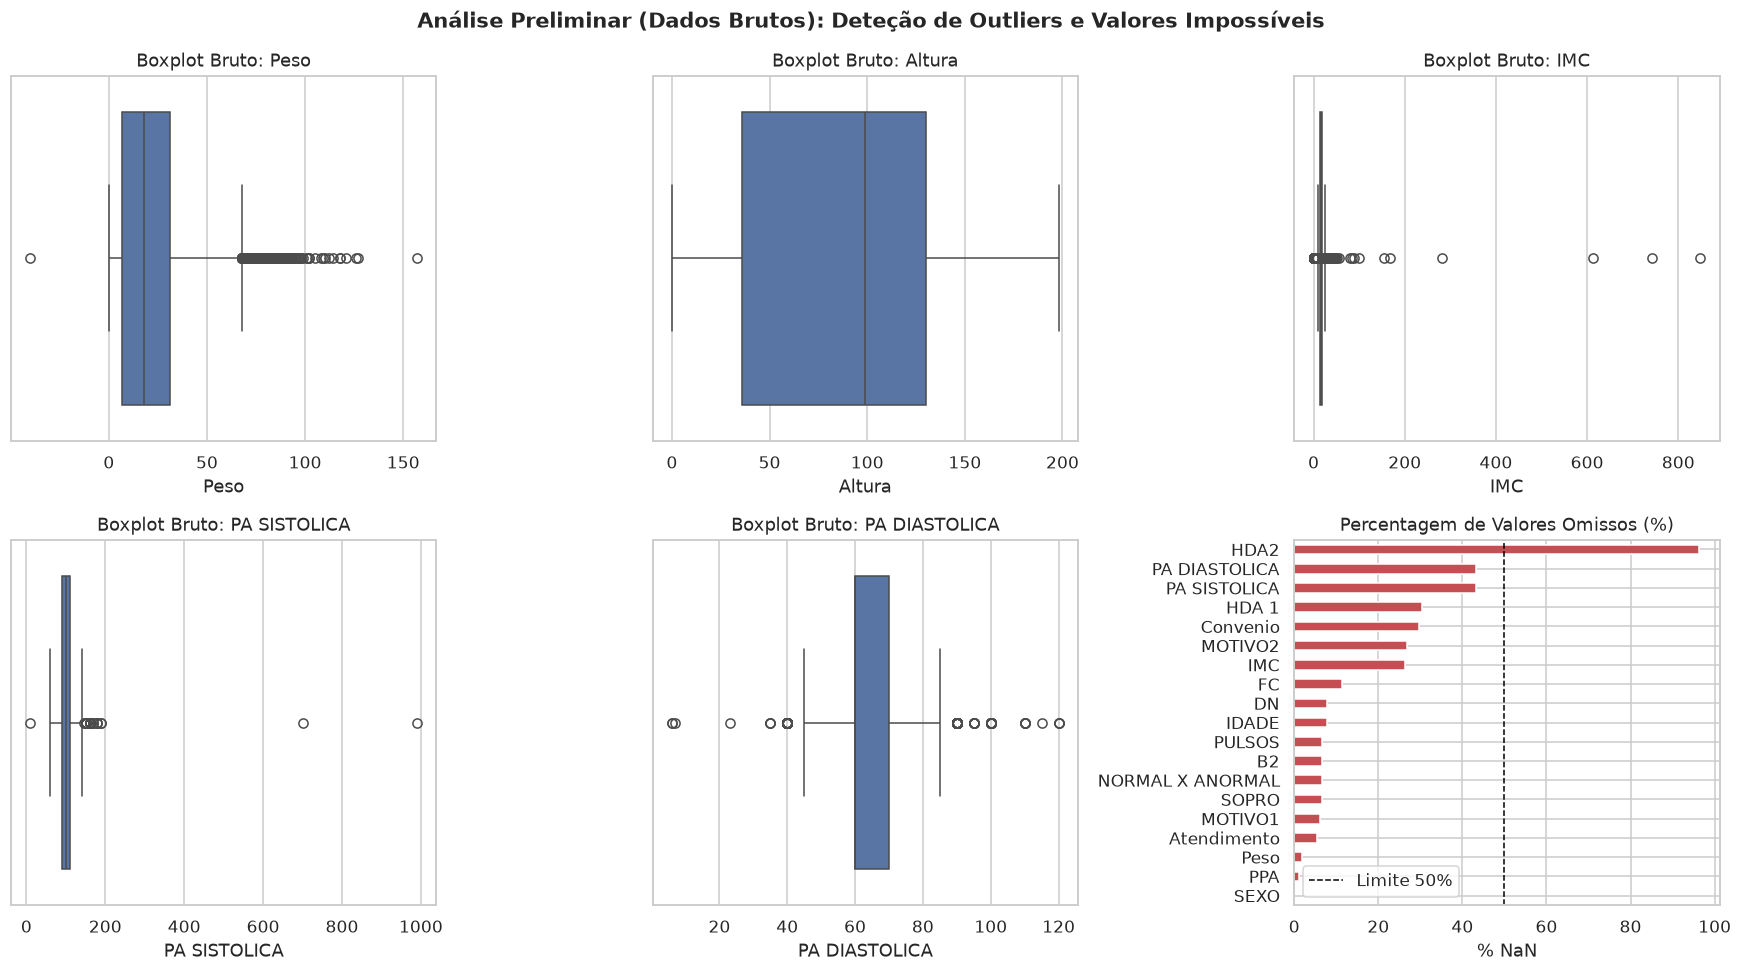


Registos duplicados (ignorando ID): 1020
IDADE (tipo object) -> min: -113.18, max: 71.81, não-numéricos: 120
FC (tipo object) -> min: 8.0, max: 9288.0, não-numéricos: 16


In [8]:
# 1. Sumário estatístico das variáveis numéricas tal como vêm no Excel
num_cols_raw = ["Peso", "Altura", "IMC", "PA SISTOLICA", "PA DIASTOLICA"]
print("=== Sumário Estatístico das Variáveis Numéricas (Dados em Bruto) ===")
display(df_raw[num_cols_raw].describe().T)

# 2. Inspeção das categorias principais e da variável alvo
cat_check = ["NORMAL X ANORMAL", "SEXO", "PULSOS", "B2", "SOPRO", "PPA"]
for col in cat_check:
    print(f"\n--- Distribuição bruta: {col} ---")
    print(df_raw[col].value_counts(dropna=False))

# 3. Boxplots e Histogramas para expor visualmente outliers e ruído
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Análise Preliminar (Dados Brutos): Deteção de Outliers e Valores Impossíveis", fontsize=14, fontweight="bold")

for idx, col in enumerate(num_cols_raw):
    row, c = divmod(idx, 3)
    sns.boxplot(x=df_raw[col], ax=axes[row, c], color="#4C72B0")
    axes[row, c].set_title(f"Boxplot Bruto: {col}")
    axes[row, c].set_xlabel(col)

# Último subplot: contagem de valores omissos por coluna (%)
missing_pct = (df_raw.isnull().sum() / len(df_raw) * 100).sort_values(ascending=True)
missing_pct[missing_pct > 0].plot(kind="barh", ax=axes[1, 2], color="#C44E52")
axes[1, 2].axvline(50, color="black", linestyle="--", linewidth=1, label="Limite 50%")
axes[1, 2].set_title("Percentagem de Valores Omissos (%)")
axes[1, 2].set_xlabel("% NaN")
axes[1, 2].legend()

plt.tight_layout()
plt.show()

# 4. Confirmação pontual de duplicados e das colunas textuais IDADE e FC
print(f"\nRegistos duplicados (ignorando ID): {df_raw.drop(columns=['ID']).duplicated().sum()}")
for col in ["IDADE", "FC"]:
    s_num = pd.to_numeric(df_raw[col], errors="coerce")
    print(f"{col} (tipo {df_raw[col].dtype}) -> min: {s_num.min()}, max: {s_num.max()}, não-numéricos: {df_raw[col].notnull().sum() - s_num.notnull().sum()}")

### 1.2 Principais Inconsistências Detetadas (Lista de Alterações Necessárias)

A análise preliminar aos dados em bruto revelou os seguintes problemas críticos que exigem intervenção na etapa de pré-processamento:

1. **Atributos Irrelevantes ou Excessivamente Omissos:**
  - `ID` é apenas um identificador sequencial sem poder preditivo — deve ser removido.
  - `HDA 2` apresenta **96,35% de valores omissos** (17 221 `NaN`), ultrapassando largamente o limiar de 50%–70% recomendado na literatura — deve ser removida.
2. **Registos Duplicados e Variável Alvo Omissa:**
  - Existem **1 020 registos inteiramente duplicados** (quando ignorada a coluna `ID`), que enviesariam o treino e a avaliação dos modelos.
  - A variável alvo `NORMAL X ANORMAL` contém **1 168 registos sem diagnóstico (`NaN`)**, os quais não podem ser utilizados na aprendizagem supervisionada.
3. **Inconsistências Textuais e Categorias Duplicadas:**
  - `NORMAL X ANORMAL`: existem entradas isoladas escritas como `anormal` (1) e `Normais` (1) além de `Normal` e `Anormal`.
  - `SEXO`: coexistem `M`, `Masculino`, `masculino`, `F`, `Feminino` e `Indeterminado`.
  - `SOPRO` e `PULSOS`: diferenças de capitalização (`Sistólico` vs. `sistólico`, `Normais` vs. `NORMAIS`, `Amplos` vs. `AMPLOS`).
4. **Erros de Tipo de Dados (`object` em vez de numérico):**
  - `IDADE` e `FC` (Frequência Cardíaca) foram importadas como texto (`object`) devido à presença de caracteres não numéricos ou formatações inválidas.
5. **Valores Fisiologicamente Impossíveis e Ruído:**
  - `Peso`: apresenta valores negativos (mínimo de **-40 kg**) e zeros.
  - `Altura`: apresenta múltiplos registos iguais a **0 cm**.
  - `IDADE`: apresenta valores negativos (ex.: `-4.05` anos) resultantes de erros de introdução nas datas (`Atendimento < DN`) ou idades superiores ao escopo pediátrico (> 20 anos).
  - `IMC`: contém valores absurdos (máximo de **848**), originados por divisões com altura igual a zero ou erros de escala. Deve ser recalculado diretamente a partir de $\text{Peso} / \text{Altura (m)}^2$.
  - `PA SISTOLICA` e `PA DIASTOLICA`: contêm valores impossíveis (ex.: PAS de **990 mmHg** ou **10 mmHg**, PAD de **6 mmHg**).
6. **Erros de Fórmula no `PPA` e Engenharia de Atributos Clínicos:**
  - A coluna `PPA` contém **1 496 erros `#VALUE!`** herdados de fórmulas do Excel e **9 081 entradas `Não Calculado`**.
  - De acordo com as normas clínicas pediátricas (Circular Normativa da DGS e tabelas de tensão arterial por idade/percentil de estatura), variáveis contínuas como `IDADE`, `IMC` e `PA` devem ser avaliadas e discretizadas em intervalos clinicamente significativos.